# NEET analysis
This notebook loads the cleaned CPS ASEC data from Google Drive and takes a first look. Run it top to bottom.

## Setup
Import the tools and set the file path in one place.

In [25]:
import pandas as pd  # tables of data
import numpy as np  # math, used for weighted averages
import matplotlib.pyplot as plt  # charts

data_path = "/content/drive/My Drive/neet_data.csv"  # where the cleaned data lives on Drive
fig_path = "/content/drive/My Drive/fig1_neet_by_age_sex.png"  # where the NEET chart is saved on Drive

## Mount Google Drive
This lets Colab read files from your Drive. Colab will ask you to allow access.

In [26]:
from google.colab import drive  # Colab's Google Drive tool
drive.mount("/content/drive")  # connect Google Drive

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Load the data

In [27]:
df = pd.read_csv(data_path)  # load the cleaned data into a table

## Shape and column names
Shape is (number of people, number of variables).

In [28]:
print(df.shape)  # rows (people) and columns (variables)
print(list(df.columns))  # names of all columns

(893864, 36)
['year', 'asecwt', 'age', 'hours', 'female', 'poor', 'white', 'black', 'asian', 'hispanic', 'other_race', 'employed', 'unemployed', 'nilf', 'enrolled', 'not_enrolled', 'less_hs', 'hs_ged', 'some_college', 'bachelor_plus', 'self_emp', 'wage_salary', 'unpaid_family', 'age16_19', 'age20_24', 'age25_29', 'neet', 'not_neet', 'unemployed_neet', 'nilf_neet', 'sex_label', 'empstat_label', 'enrolled_label', 'neet_label', 'unemp_neet_label', 'nilf_neet_label']


## Summary table
All numbers use the person weight `asecwt`. N is the number of people with a value (not weighted). Mean, SD, Min and Max are weighted where it applies. Means of 0/1 variables are shares (0.5 = 50%).

In [29]:
rows = {}  # empty dictionary, one row per variable
for var in df.select_dtypes("number").columns:  # loop over the number columns
    if var == "asecwt":  # the weight itself is not summarized
        continue  # skip it
    d = df.dropna(subset=[var])  # keep people with a value for this variable
    x = d[var]  # the values
    w = d["asecwt"]  # the person weights
    mean = np.average(x, weights=w)  # weighted mean
    sd = np.sqrt(np.average((x - mean) ** 2, weights=w))  # weighted standard deviation
    rows[var] = {"N": len(d), "Mean": mean, "SD": sd, "Min": x.min(), "Max": x.max()}  # one row of the table

summary = pd.DataFrame(rows).T  # dictionary -> table, one row per variable
summary["N"] = summary["N"].astype(int)  # N is a whole number
print(summary.to_string(float_format="{:.1f}".format))  # print with 1 decimal

                      N   Mean   SD    Min    Max
year             893864 2013.4  7.6 2000.0 2026.0
age              893864   22.5  4.1   16.0   29.0
hours            491549   34.8 13.4    1.0   99.0
female           893864    0.5  0.5    0.0    1.0
poor             893548    0.2  0.4    0.0    1.0
white            893864    0.6  0.5    0.0    1.0
black            893864    0.1  0.3    0.0    1.0
asian            893864    0.1  0.2    0.0    1.0
hispanic         893864    0.2  0.4    0.0    1.0
other_race       893864    0.0  0.2    0.0    1.0
employed         887550    0.6  0.5    0.0    1.0
unemployed       887550    0.1  0.2    0.0    1.0
nilf             887550    0.3  0.5    0.0    1.0
enrolled         727214    0.5  0.5    0.0    1.0
not_enrolled     727214    0.5  0.5    0.0    1.0
less_hs          893864    0.3  0.4    0.0    1.0
hs_ged           893864    0.3  0.4    0.0    1.0
some_college     893864    0.3  0.5    0.0    1.0
bachelor_plus    893864    0.2  0.4    0.0    1.0


## NEET rate by year, age group and sex
The NEET rate is the weighted percent of people with `neet = 1`, among people whose `neet` is known. People with a missing `neet` are left out (they are not counted as 0). Rows are survey years. Columns are age group first, then sex (Men, then Women). Weights use `asecwt`.

In [30]:
def wmean(data, var):  # weighted mean of one variable
    d = data.dropna(subset=[var])  # leave out people with a missing value
    return np.average(d[var], weights=d["asecwt"])  # weighted average using asecwt

if "agegrp" not in df.columns:  # make age groups only if the file does not have them
    df["agegrp"] = pd.cut(df["age"], bins=[16, 20, 25, 30], labels=["16-19", "20-24", "25-29"], right=False)  # 16-19, 20-24, 25-29

df["sex"] = pd.Categorical(df["female"].map({0: "Men", 1: "Women"}), categories=["Men", "Women"], ordered=True)  # words for female, Men first

known = df.dropna(subset=["neet"])  # keep only people whose neet is known
keys = ["year", "agegrp", "sex"]  # group by year, age group, sex

rate = known.groupby(keys, observed=True).apply(wmean, "neet", include_groups=False) * 100  # weighted NEET rate in percent
rate = rate.unstack(["agegrp", "sex"])  # years down the rows, age group and sex across
people = known.groupby(keys, observed=True).size().unstack(["agegrp", "sex"]).astype(float)  # unweighted respondents, same layout

rate.loc[rate.index < 2013, "25-29"] = np.nan  # ages 25-29 before 2013: blank, not 0
people.loc[people.index < 2013, "25-29"] = np.nan  # same blanks in the counts

print("NEET rate, % of people (weighted with asecwt). Rows: survey year.")  # table title
print(rate.to_string(float_format="{:.1f}".format, na_rep=""))  # rate table, 1 decimal, blanks stay blank
print()  # empty line
print("Unweighted number of respondents in each cell (neet not missing).")  # counts title
print(people.to_string(float_format="{:.0f}".format, na_rep=""))  # counts table, whole numbers, blanks stay blank
print()  # empty line
print("Ages 25-29 are blank before 2013 because school enrollment (SCHLCOLL) was not asked of that age group.")  # required note

NEET rate, % of people (weighted with asecwt). Rows: survey year.
agegrp 16-19       20-24       25-29      
sex      Men Women   Men Women   Men Women
year                                      
2000     6.4   8.7  11.2  19.0            
2001     7.0   9.4  13.3  18.9            
2002     8.3   8.5  14.3  20.2            
2003     9.1   8.5  13.5  20.0            
2004     6.9   7.4  13.9  20.3            
2005     7.7   8.3  14.1  20.7            
2006     7.1   8.1  12.9  19.8            
2007     7.2   7.7  12.7  19.2            
2008     7.3   8.0  13.6  19.8            
2009     9.6   8.0  19.3  20.4            
2010     9.4   8.5  20.1  22.3            
2011     7.7   8.0  19.1  20.8            
2012     7.9   7.6  17.0  20.1            
2013     8.7   8.4  18.0  19.6  15.9  25.3
2014     9.3   8.5  16.4  18.9  14.6  25.8
2015     9.0   8.6  15.7  19.2  13.3  24.7
2016     8.7   8.2  15.8  17.8  13.0  22.9
2017     7.1   7.0  13.5  15.3  13.3  21.8
2018     7.7   7.3  13.5  15.3 

**What one cell means.** Take the cell in the row for one survey year and the column for one age group and sex (for example, the row 2019 and the column 20-24, Women). Among women aged 20-24 in the survey of that year whose NEET status is known, it is the percent who were NEET: not employed and not in school. People are counted by how many people in the country they represent (`asecwt`), so the number describes the population, not just the people surveyed. A cell of 10.0 means 10 out of every 100 such people were NEET. The count table below it shows how many survey respondents sit behind each cell: a cell with few respondents is less reliable. A blank cell means the rate is not available, not zero.

## Chart: NEET rate by year, age group and sex
This chart draws the table above, nothing else. One panel per age group, one line for Men and one for Women. All panels share the same y-axis, which starts at 0. Blank cells (ages 25-29 before 2013) are not drawn, so there is no line across the missing years. The title is built from the table: it names the group with the highest NEET rate in the last year.

NEET rate (%), weighted with asecwt. Rows: survey year. The chart shows this table.
agegrp 16-19       20-24       25-29      
sex      Men Women   Men Women   Men Women
year                                      
2000     6.4   8.7  11.2  19.0            
2001     7.0   9.4  13.3  18.9            
2002     8.3   8.5  14.3  20.2            
2003     9.1   8.5  13.5  20.0            
2004     6.9   7.4  13.9  20.3            
2005     7.7   8.3  14.1  20.7            
2006     7.1   8.1  12.9  19.8            
2007     7.2   7.7  12.7  19.2            
2008     7.3   8.0  13.6  19.8            
2009     9.6   8.0  19.3  20.4            
2010     9.4   8.5  20.1  22.3            
2011     7.7   8.0  19.1  20.8            
2012     7.9   7.6  17.0  20.1            
2013     8.7   8.4  18.0  19.6  15.9  25.3
2014     9.3   8.5  16.4  18.9  14.6  25.8
2015     9.0   8.6  15.7  19.2  13.3  24.7
2016     8.7   8.2  15.8  17.8  13.0  22.9
2017     7.1   7.0  13.5  15.3  13.3  21.8
2018     7.7 

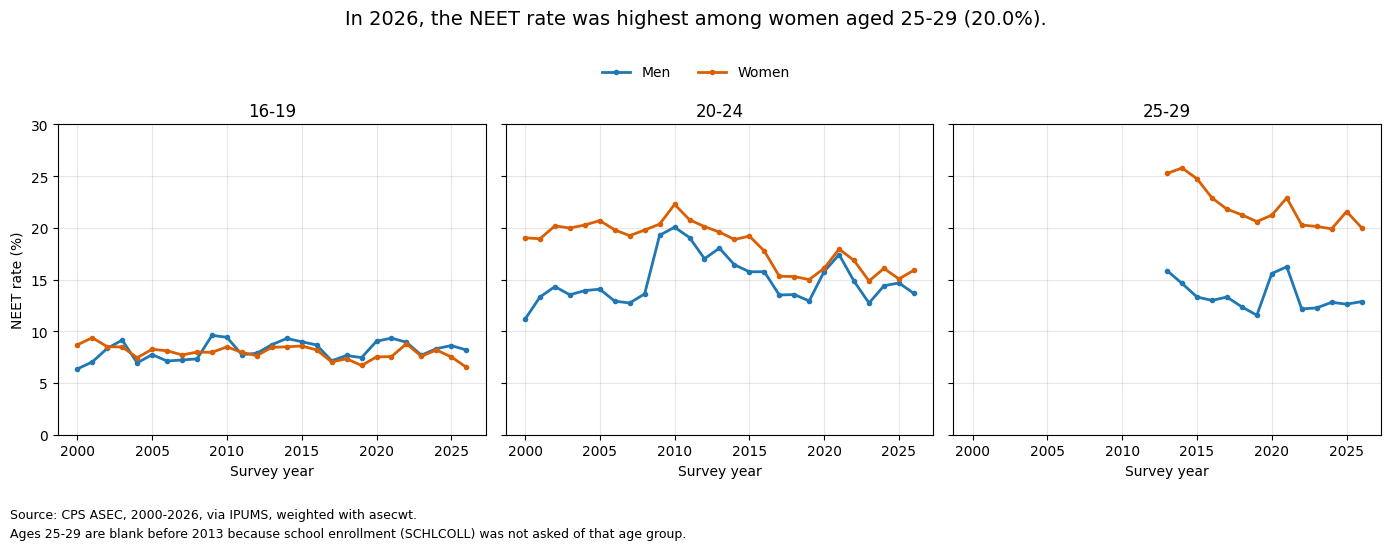

In [31]:
print("NEET rate (%), weighted with asecwt. Rows: survey year. The chart shows this table.")  # table title
print(rate.to_string(float_format="{:.1f}".format, na_rep=""))  # table, 1 decimal, blanks stay blank

age_groups = ["16-19", "20-24", "25-29"]  # one panel per age group
colors = {"Men": "#1f77b4", "Women": "#d95f02"}  # same color for each sex in every panel
first_year = int(rate.index.min())  # first year in the table
last_year = int(rate.index.max())  # last year in the table
ymax = int(np.floor(rate.max().max() / 5) * 5 + 5)  # round number just above the highest value

last_row = rate.loc[last_year]  # NEET rates in the last year
best = last_row.idxmax()  # (age group, sex) with the highest rate that year
title = f"In {last_year}, the NEET rate was highest among {best[1].lower()} aged {best[0]} ({last_row[best]:.1f}%)."  # finding, taken from the table

fig, axes = plt.subplots(1, 3, figsize=(14, 5.5), sharex=True, sharey=True)  # three panels, same x and y axes
for ax, age in zip(axes, age_groups):  # one panel per age group
    for sex in ["Men", "Women"]:  # one line per sex
        ax.plot(rate.index, rate[(age, sex)], color=colors[sex], marker="o", markersize=3, linewidth=2, label=sex)  # blank years are not drawn
    ax.set_title(age)  # panel title is the age group
    ax.set_xlabel("Survey year")  # x-axis label
    ax.set_ylim(0, ymax)  # y-axis starts at 0 in every panel
    ax.set_yticks(range(0, ymax + 1, 5))  # y ticks every 5 points, starting at 0
    ax.set_xticks(range(first_year, last_year + 1, 5))  # x ticks every 5 years
    ax.grid(True, alpha=0.3)  # light grid
axes[0].set_ylabel("NEET rate (%)")  # y-axis label (shared by all panels)

handles, labels = axes[0].get_legend_handles_labels()  # Men and Women lines
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.90), ncol=2, frameon=False)  # one legend for all panels
fig.suptitle(title, fontsize=14, y=0.98)  # chart title
fig.tight_layout(rect=[0, 0.1, 1, 0.9])  # leave room for the title, legend and notes
fig.text(0.01, 0.055, f"Source: CPS ASEC, {first_year}-{last_year}, via IPUMS, weighted with asecwt.", fontsize=9)  # source note
fig.text(0.01, 0.02, "Ages 25-29 are blank before 2013 because school enrollment (SCHLCOLL) was not asked of that age group.", fontsize=9)  # required note
fig.savefig(fig_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart